# PDAN8412/w Part 3: Book cover classification using CNNs

**Portfolio of Evidence | Image recognition with TensorFlow**  
**Student number:** ST10123828

## 1. Introduction

This study explores whether a convolutional neural network (CNN) can classify a book into one of 30 categories by examining its cover image. The project continues the publishing-company scenario from Parts 1 and 2. In this case, image recognition could help the publisher organise a large catalogue of books and review how visual design relates to the categories under which books are sold.

I use BookCover30, a research dataset developed by Iwana and colleagues. It includes 57,000 labelled book covers divided into 51,300 training records and 5,700 test records. The images are associated with book categories such as romance, literature, biographies and computing. The category label is the outcome that the CNN attempts to predict.

A book cover does not always reveal the content or genre of a book. Some categories share similar visual styles, and titles or author names printed on covers may influence the prediction. The aim is therefore to evaluate how well the model can recognise the dataset's assigned categories, rather than to claim that a cover alone can establish a book's true genre.

**Dataset:** Iwana et al. (2016), *Judging a Book by its Cover*. [Official repository](https://github.com/uchidalab/book-dataset).  
**Images:** the researchers' BookCover30 archive, containing resized covers at 224 × 224 pixels.  
**Use:** academic analysis and model evaluation, with attribution to the dataset creators. The source repository notes that book-cover images are subject to Amazon's copyright.

## 2. Plan of analysis

| Stage | Approach | Reason |
|---|---|---|
| Dataset review | Examine the official labels, image references and category definitions | Check whether the data is appropriate for supervised image classification |
| Spark analysis | Count records, inspect category frequencies, missing information and duplicates | Establish data quality before selecting training observations |
| Image review | Confirm which images exist and inspect their appearance and quality | Identify potential loading problems and visual differences |
| Data preparation | Preserve the official test partition and select a balanced training and validation sample | Keep evaluation independent while making training manageable on a personal laptop |
| Baseline CNN | Train a small convolutional model with TensorFlow | Establish a reference result |
| Improved CNN | Add controlled augmentation, batch normalisation and dropout | Investigate whether the model generalises better |
| Evaluation | Compare validation results, then assess the selected model on the test set | Report performance without using the test set to select the model |
| Reporting | Export numbered figures, tables and a concise summary | Link each finding to the business question and assignment rubric |

The full dataset is used for metadata EDA. The CNN uses a configurable, stratified subset of the official training data to reduce the computational load. The original test partition remains separate. These decisions and the final sample counts are recorded during execution.

## 3. Environment and reproducibility

This notebook is designed for a Python 3.11 environment with PySpark, TensorFlow, NumPy, pandas, Pillow, scikit-learn and Matplotlib installed. The `requirements.txt` file lists the packages.

The first run downloads the book-cover image archive to a cache folder in the user's home directory. The archive is read directly. There is no need to extract thousands of JPG files into the submission folder. If an automatic Google Drive download is blocked, the code provides a link and can also find the archive in the Windows Downloads folder.

I use a fixed random seed for data sampling. Training can still vary slightly between computers because of differences in TensorFlow and hardware operations.

In [11]:
from pathlib import Path
import os, sys, re, io, zipfile, math, random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, UnidentifiedImageError
from IPython.display import display, Markdown
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
import tensorflow as tf

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

PROJECT_DIR = Path.cwd()
META = PROJECT_DIR / 'metadata'
OUT = PROJECT_DIR / 'outputs'
FIGURES = OUT / 'figures'
CACHE_DIR = Path.home() / 'PDAN8412_BookCover30_Cache'
for path in [OUT, FIGURES, CACHE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

for filename in ['book30-listing-train.csv', 'book30-listing-test.csv', 'categories.csv']:
    if not (META / filename).is_file():
        raise FileNotFoundError(f'Missing metadata/{filename}. Open Jupyter from the extracted Part 3 project folder.')

IMG_SIZE = 96                  # smaller than the original 224x224 covers for CPU training
BATCH_SIZE = 32
TRAIN_PER_CLASS = 500          # 15,000 training images across 30 classes
VAL_PER_CLASS = 100           # 3,000 validation images, taken only from official training data
TEST_PER_CLASS = None         # None means all 5,700 official test records
EPOCHS_BASELINE = 5
EPOCHS_IMPROVED = 7
DRIVE_FILE_ID = '1LVWYXn2WdF-7NuLbl_LyyEwXSvIJUdPr'

print('Python:', sys.version.split()[0])
print('TensorFlow:', tf.__version__)
print('Project folder:', PROJECT_DIR)
print('Image cache:', CACHE_DIR)
print('GPU devices:', tf.config.list_physical_devices('GPU'))

Python: 3.11.18
TensorFlow: 2.21.0
Project folder: C:\Users\anphewa\PDAN8412_Part3_ST10123828_BookCover30
Image cache: C:\Users\anphewa\PDAN8412_BookCover30_Cache
GPU devices: []


In [12]:
# Use one numbering sequence for notebook figures, saved images and the future report.
FIGURE_RECORDS = []

def save_figure(number, title, fig):
    if any(r['number'] == number for r in FIGURE_RECORDS):
        raise ValueError(f'Figure {number} was already used. Keep figure numbers unique.')
    safe_title = re.sub(r'[^A-Za-z0-9]+', '_', title).strip('_')[:70]
    fig.suptitle(f'Figure {number}. {title}', fontsize=13, fontweight='semibold', y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.955))
    path = FIGURES / f'Figure_{number:02d}_{safe_title}.png'
    fig.savefig(path, dpi=160, bbox_inches='tight')
    FIGURE_RECORDS.append({'number': number, 'caption': title, 'file': path.name})
    plt.show()
    print(f'Saved: {path.name}')

## 4. Exploratory Data Analysis with Apache Spark

The original train and test listing files include the image filename, URL, book title, author and category. I use Spark to assess all 57,000 observations before working with the image archive. This helps identify missing or repeated values and confirms that the category labels are appropriate for supervised classification.

In [13]:

# PySpark is required by the Part 3 assessment, even though TensorFlow trains the CNN.
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable

from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder
         .master('local[2]')
         .appName('PDAN8412_Part3_BookCover30')
         .config('spark.ui.enabled', 'false')
         .config('spark.sql.shuffle.partitions', '8')
         .getOrCreate())

columns = ['asin', 'filename', 'image_url', 'title', 'author', 'category_id', 'category']

def load_spark_listing(filename, partition):
    df = (spark.read
          .option('header', 'false')
          .option('multiLine', 'true')
          .option('quote', '"')
          .option('escape', '"')
          .option('encoding', 'ISO-8859-1')
          .csv(str(META / filename)).toDF(*columns))

    return (df.withColumn('category_id', F.col('category_id').cast('int'))
              .withColumn('partition', F.lit(partition)))

spark_train = load_spark_listing('book30-listing-train.csv', 'train')
spark_test = load_spark_listing('book30-listing-test.csv', 'test')
spark_all = spark_train.unionByName(spark_test)

spark_counts = {
    'train': spark_train.count(),
    'test': spark_test.count(),
    'total': spark_all.count()
}

print('Spark version:', spark.version)
print('Spark record counts:', spark_counts)

spark_all.printSchema()
spark_all.select('filename', 'title', 'category').show(5, truncate=35)

assert spark_counts['total'] >= 10_000, 'The assessment requires at least 10,000 records.'


Spark version: 4.2.0
Spark record counts: {'train': 51300, 'test': 5700, 'total': 57000}
root
 |-- asin: string (nullable = true)
 |-- filename: string (nullable = true)
 |-- image_url: string (nullable = true)
 |-- title: string (nullable = true)
 |-- author: string (nullable = true)
 |-- category_id: integer (nullable = true)
 |-- category: string (nullable = true)
 |-- partition: string (nullable = false)

+--------------+-----------------------------------+----------------------------+
|      filename|                              title|                    category|
+--------------+-----------------------------------+----------------------------+
|1588345297.jpg|With Schwarzkopf: Life Lessons o...|       Biographies & Memoirs|
|1404803335.jpg|Magnets: Pulling Together, Pushi...|            Children's Books|
|1446276082.jpg|Energy Security (SAGE Library of...|Engineering & Transportation|
|1491522666.jpg|An Amish Gathering: Life in Lanc...|    Christian Books & Bibles|
|0970096410.j

In [14]:
# Assess data quality before choosing records for training.
missing_expressions = [F.sum(F.when(F.col(c).isNull() | (F.trim(F.col(c).cast('string')) == ''), 1).otherwise(0)).alias(c)
                       for c in columns]
missing_spark = spark_all.select(*missing_expressions).first().asDict()
quality_stats = {
    'duplicate_filenames': spark_all.groupBy('filename').count().filter(F.col('count') > 1).count(),
    'duplicate_asins': spark_all.groupBy('asin').count().filter(F.col('count') > 1).count(),
    'invalid_category_ids': spark_all.filter(F.col('category_id').isNull() | (F.col('category_id') < 0) | (F.col('category_id') > 29)).count(),
    'train_test_filename_overlap': spark_train.select('filename').intersect(spark_test.select('filename')).count()
}
print('Missing values:', missing_spark)
print('Data quality:', quality_stats)

spark_genres = (spark_all.groupBy('partition', 'category_id', 'category')
               .count().orderBy('partition', 'category_id'))
rows = [r.asDict() for r in spark_genres.collect()]
spark_genre_table = pd.DataFrame(rows)
spark_genre_table.to_csv(OUT / 'spark_category_counts.csv', index=False)
pd.DataFrame([missing_spark]).to_csv(OUT / 'spark_missing_values.csv', index=False)
pd.DataFrame([quality_stats]).to_csv(OUT / 'spark_data_quality.csv', index=False)
display(spark_genre_table.head(10))

with open(OUT / 'spark_execution_summary.txt', 'w', encoding='utf-8') as f:
    f.write('PySpark executed successfully\n')
    f.write(f'Spark version: {spark.version}\n')
    f.write(f'Records: {spark_counts}\n')
    f.write(f'Missing fields: {missing_spark}\n')
    f.write(f'Data quality: {quality_stats}\n')

assert quality_stats['invalid_category_ids'] == 0, 'Unexpected category labels need investigation.'
assert quality_stats['train_test_filename_overlap'] == 0, 'Training and test images overlap.'
print('Spark analysis completed and results saved to outputs/.')
spark.stop()

Missing values: {'asin': 0, 'filename': 0, 'image_url': 0, 'title': 0, 'author': 3825, 'category_id': 0, 'category': 0}
Data quality: {'duplicate_filenames': 0, 'duplicate_asins': 0, 'invalid_category_ids': 0, 'train_test_filename_overlap': 0}


,partition,category_id,category,count
0,test,0,Arts & Photography,190
1,test,1,Biographies & Memoirs,190
2,test,2,Business & Money,190
3,test,3,Calendars,190
4,test,4,Children's Books,190
5,test,5,Comics & Graphic Novels,190
6,test,6,Computers & Technology,190
7,test,7,"Cookbooks, Food & Wine",190
8,test,8,"Crafts, Hobbies & Home",190
9,test,9,Christian Books & Bibles,190


Spark analysis completed and results saved to outputs/.


### 4.1 Category frequencies and missing information

BookCover30 was designed with equal numbers of examples per category. Figures 1 and 2 show whether the released listing files retain this balance. Figure 3 summarises missing metadata fields. These checks are useful because an imbalanced target or incomplete labels could affect how fairly the CNN is evaluated.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


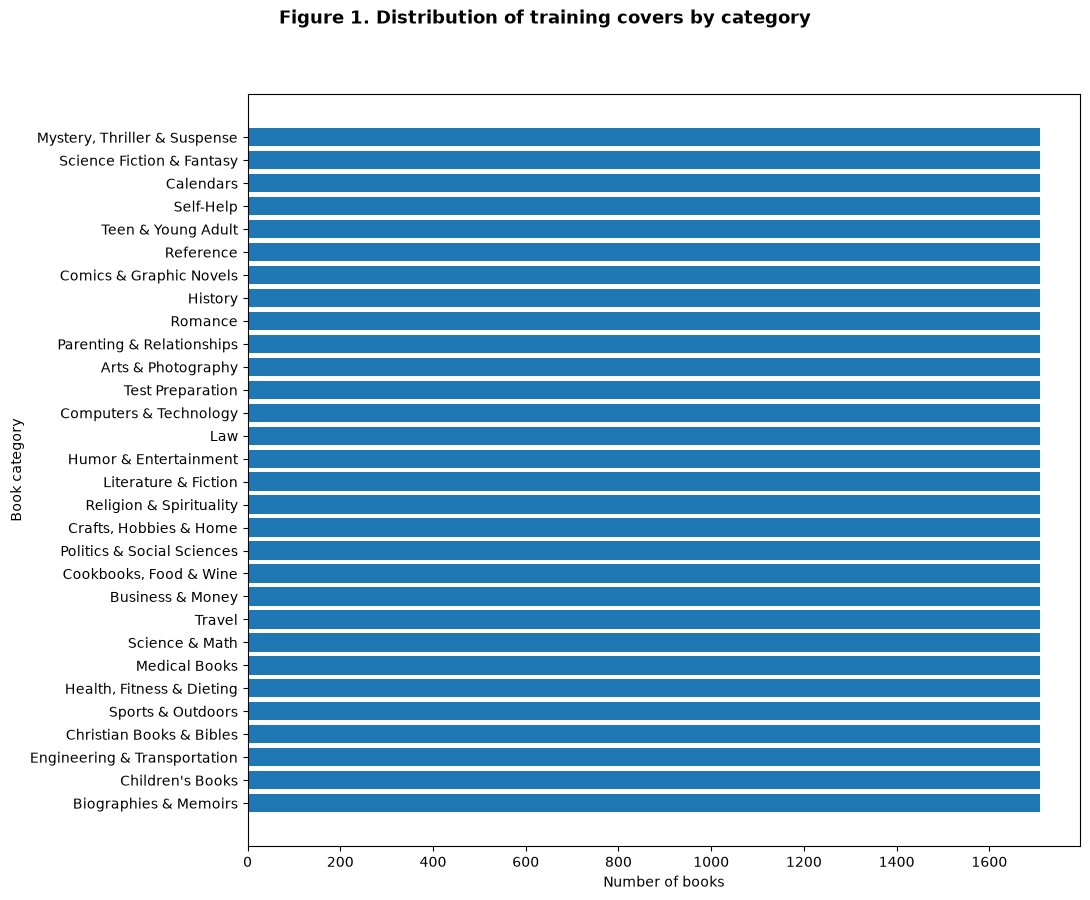

Saved: Figure_01_Distribution_of_training_covers_by_category.png


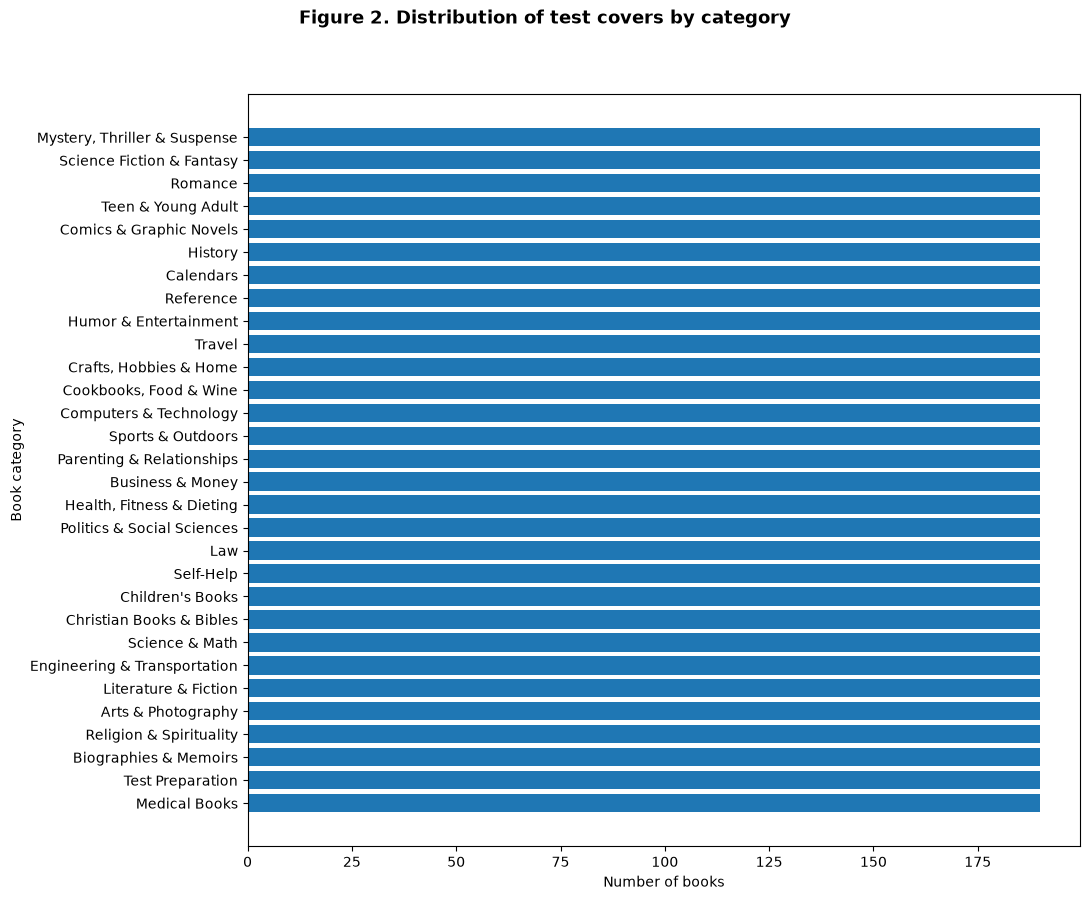

Saved: Figure_02_Distribution_of_test_covers_by_category.png


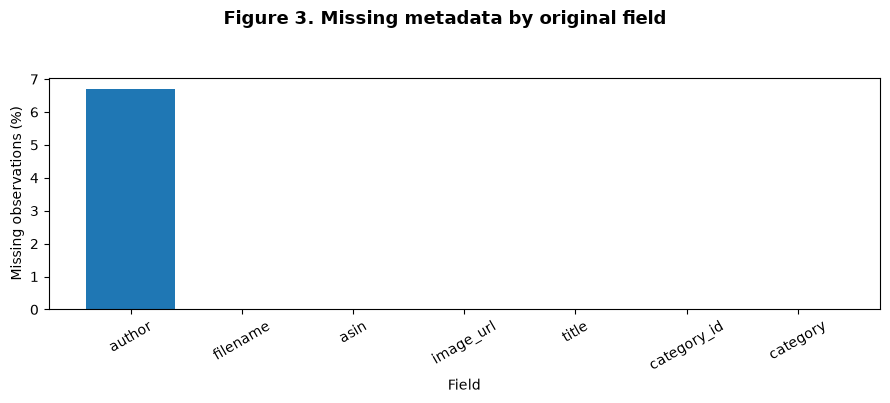

Saved: Figure_03_Missing_metadata_by_original_field.png
Train class counts: {'count': 30.0, 'mean': 1710.0, 'std': 0.0, 'min': 1710.0, '25%': 1710.0, '50%': 1710.0, '75%': 1710.0, 'max': 1710.0}
Test class counts: {'count': 30.0, 'mean': 190.0, 'std': 0.0, 'min': 190.0, '25%': 190.0, '50%': 190.0, '75%': 190.0, 'max': 190.0}


In [15]:
category_lookup = pd.read_csv(META / 'categories.csv').set_index('category_id')['category'].to_dict()
train_listing = pd.read_csv(META / 'book30-listing-train.csv', header=None, names=columns,
                            encoding='latin-1', dtype={'asin': str})
test_listing = pd.read_csv(META / 'book30-listing-test.csv', header=None, names=columns,
                           encoding='latin-1', dtype={'asin': str})
for df in [train_listing, test_listing]:
    df['category_id'] = df['category_id'].astype(int)
    df['filename'] = df['filename'].astype(str).str.strip()

assert len(train_listing) == spark_counts['train'] and len(test_listing) == spark_counts['test']
assert set(train_listing['category_id']) == set(range(30))

for num, frame, title in [(1, train_listing, 'Distribution of training covers by category'),
                           (2, test_listing, 'Distribution of test covers by category')]:
    series = frame['category_id'].map(category_lookup).value_counts().sort_values()
    fig, ax = plt.subplots(figsize=(11, 9))
    ax.barh(series.index, series.values)
    ax.set_xlabel('Number of books')
    ax.set_ylabel('Book category')
    save_figure(num, title, fig)

missing_pct = pd.Series(missing_spark).sort_values(ascending=False) / spark_counts['total'] * 100
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(missing_pct.index, missing_pct.values)
ax.set_ylabel('Missing observations (%)')
ax.set_xlabel('Field')
ax.tick_params(axis='x', labelrotation=30)
save_figure(3, 'Missing metadata by original field', fig)
print('Train class counts:', train_listing['category_id'].value_counts().describe().to_dict())
print('Test class counts:', test_listing['category_id'].value_counts().describe().to_dict())

## 5. Download and inspect the actual book covers

The listing files do not contain the images themselves. This section looks for the official `title30cat.zip` archive in the local cache or Downloads folder. If it cannot find a usable copy, it attempts to download the archive from the researchers' Google Drive link.

The images stay in their ZIP file during analysis and training. This saves disk space compared with extracting every cover. On first use, a working internet connection and enough free storage are still necessary. The file remains in the cache for future runs.

In [16]:
IMAGE_ARCHIVE_NAME = 'title30cat.zip'
GOOGLE_DRIVE_VIEW = f'https://drive.google.com/file/d/{DRIVE_FILE_ID}/view'

candidates = [CACHE_DIR / IMAGE_ARCHIVE_NAME,
              Path.home() / 'Downloads' / IMAGE_ARCHIVE_NAME,
              PROJECT_DIR / IMAGE_ARCHIVE_NAME]

def valid_archive(path):
    return path.is_file() and path.stat().st_size > 20_000_000 and zipfile.is_zipfile(path)

archive_path = next((p for p in candidates if valid_archive(p)), None)
if archive_path is None:
    import gdown
    destination = CACHE_DIR / IMAGE_ARCHIVE_NAME
    print('The image archive was not found. Attempting the official Google Drive download.')
    print('Official link:', GOOGLE_DRIVE_VIEW)
    try:
        result = gdown.download(id=DRIVE_FILE_ID, output=str(destination), quiet=False)
    except Exception as exc:
        result = None
        print('Automatic download could not complete:', str(exc)[:300])
    if result and valid_archive(destination):
        archive_path = destination
    else:
        # Some Google Drive links require an interactive browser download.
        if destination.exists() and not valid_archive(destination):
            destination.unlink()
        raise RuntimeError(
            'The image archive could not be downloaded automatically. Open this link in your browser: '
            + GOOGLE_DRIVE_VIEW + '\nDownload title30cat.zip into your Windows Downloads folder '
            '(do not extract it), then rerun this cell. The notebook will find it automatically.')

print('Using image archive:', archive_path)
print(f'Archive size: {archive_path.stat().st_size / (1024**2):,.1f} MB')
with zipfile.ZipFile(archive_path, 'r') as za:
    jpg_members = [i.filename for i in za.infolist() if not i.is_dir() and i.filename.lower().endswith(('.jpg', '.jpeg', '.png'))]
print('Image files found in archive:', len(jpg_members))
if len(jpg_members) < 10_000:
    raise ValueError('The downloaded archive does not contain the required number of image files.')

Using image archive: C:\Users\anphewa\Downloads\title30cat.zip
Archive size: 657.4 MB
Image files found in archive: 57000


,partition,records,available_images,missing_images
0,train,51300,51300,0
1,test,5700,5700,0


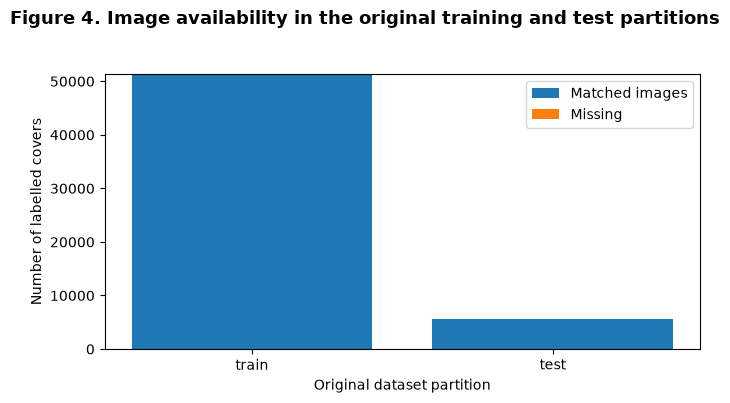

Saved: Figure_04_Image_availability_in_the_original_training_and_test_partitions.png


In [17]:
# Map filenames from the original labels to files inside the ZIP, regardless of ZIP subfolders.
from collections import defaultdict
with zipfile.ZipFile(archive_path, 'r') as za:
    map_items = defaultdict(list)
    for name in jpg_members:
        map_items[Path(name).name.lower()].append(name)

filename_map = {name: members[0] for name, members in map_items.items() if len(members) == 1}
ambiguous = [name for name, members in map_items.items() if len(members) != 1]
if ambiguous:
    print(f'Warning: {len(ambiguous)} filenames occur more than once in the archive and will be excluded until checked.')

train_listing['zip_member'] = train_listing['filename'].str.lower().map(filename_map)
test_listing['zip_member'] = test_listing['filename'].str.lower().map(filename_map)
availability = pd.DataFrame({
    'partition': ['train', 'test'],
    'records': [len(train_listing), len(test_listing)],
    'available_images': [train_listing['zip_member'].notna().sum(), test_listing['zip_member'].notna().sum()]})
availability['missing_images'] = availability['records'] - availability['available_images']
display(availability)
availability.to_csv(OUT / 'image_archive_availability.csv', index=False)
if availability['available_images'].sum() < 10_000:
    raise ValueError('Fewer than 10,000 labelled images could be matched to the archive.')

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(availability['partition'], availability['available_images'], label='Matched images')
ax.bar(availability['partition'], availability['missing_images'], bottom=availability['available_images'], label='Missing')
ax.set_ylabel('Number of labelled covers')
ax.set_xlabel('Original dataset partition')
ax.legend()
save_figure(4, 'Image availability in the original training and test partitions', fig)

### 5.1 Image quality and visual characteristics

I inspect a sample of actual book covers to confirm that the image data can be opened and converted to RGB. The brightness summaries are descriptive. They are not used as a direct replacement for the original images during CNN training.

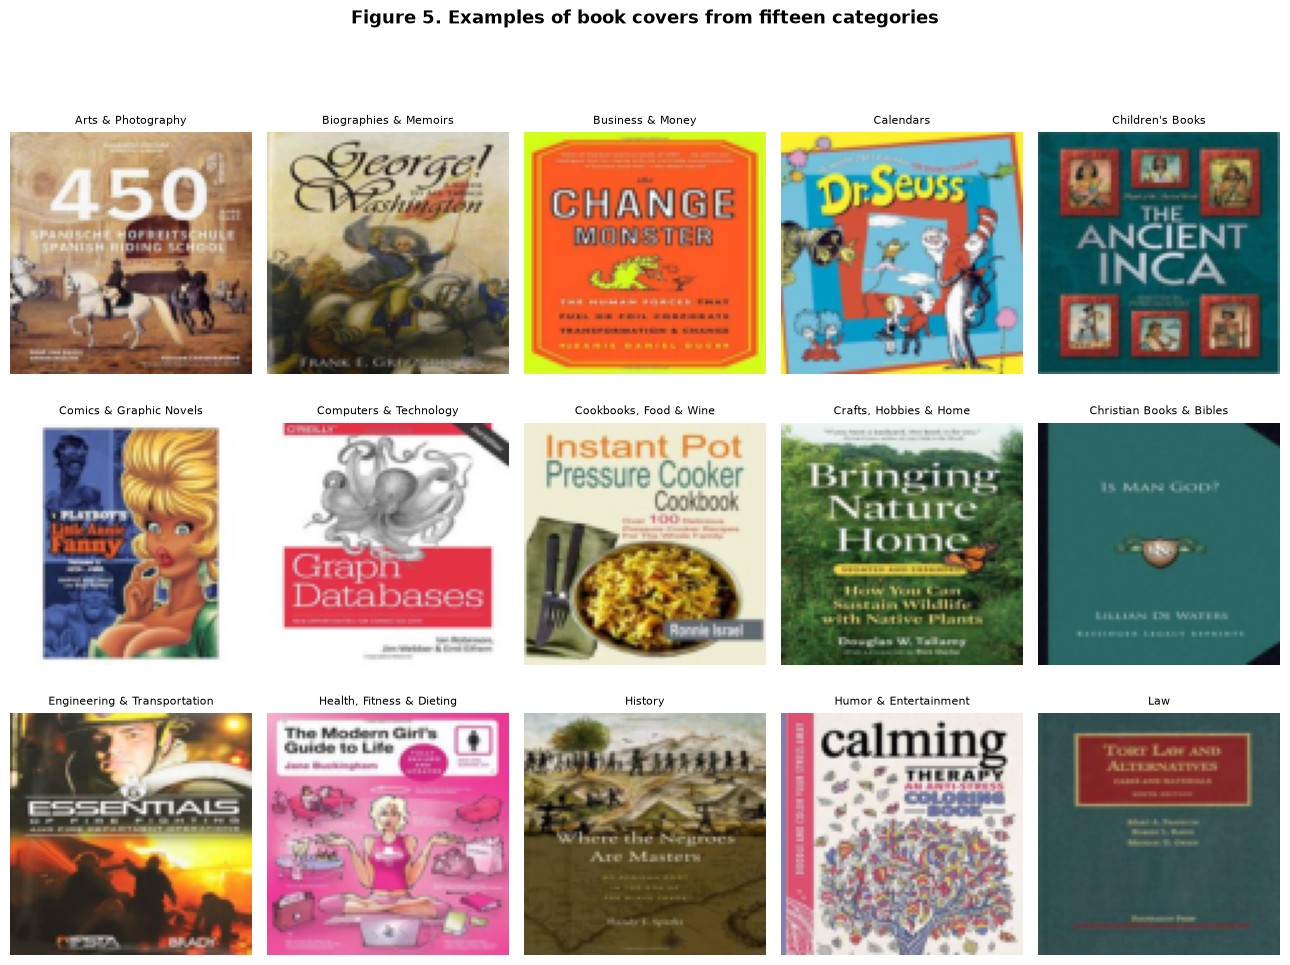

Saved: Figure_05_Examples_of_book_covers_from_fifteen_categories.png
Image samples checked: 360 ; unreadable: 0


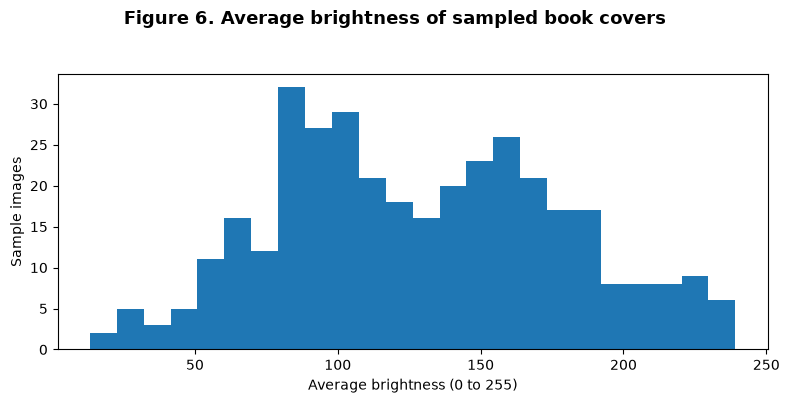

Saved: Figure_06_Average_brightness_of_sampled_book_covers.png


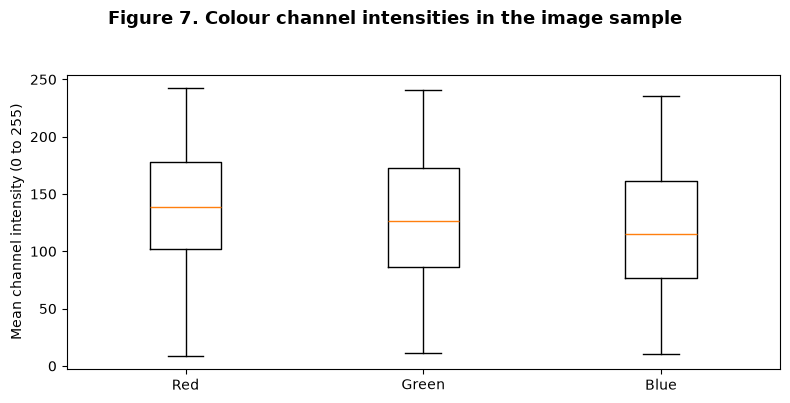

Saved: Figure_07_Colour_channel_intensities_in_the_image_sample.png


In [18]:
# These helper functions read individual covers straight from the compressed archive.
RESAMPLING = Image.Resampling.BILINEAR

def read_cover(zip_file, member, size=IMG_SIZE):
    with zip_file.open(member) as handle:
        raw = handle.read()
    with Image.open(io.BytesIO(raw)) as im:
        rgb = ImageOps.exif_transpose(im).convert('RGB').resize((size, size), RESAMPLING)
        return np.asarray(rgb, dtype=np.uint8)

available_train = train_listing.dropna(subset=['zip_member']).copy()
preview = (available_train.groupby('category_id', group_keys=False)
           .sample(n=1, random_state=SEED).sort_values('category_id').head(15))
fig, axes = plt.subplots(3, 5, figsize=(13, 10))
with zipfile.ZipFile(archive_path, 'r') as za:
    for ax, (_, row) in zip(axes.flat, preview.iterrows()):
        image_arr = read_cover(za, row['zip_member'])
        ax.imshow(image_arr)
        ax.set_title(category_lookup[row['category_id']], fontsize=8)
        ax.axis('off')
save_figure(5, 'Examples of book covers from fifteen categories', fig)

sample_eda = available_train.sample(n=min(360, len(available_train)), random_state=SEED)
brightness = []
mean_rgb = []
image_errors = []
with zipfile.ZipFile(archive_path, 'r') as za:
    for _, row in sample_eda.iterrows():
        try:
            arr = read_cover(za, row['zip_member'])
            brightness.append((row['category_id'], arr.mean()))
            mean_rgb.append(arr.reshape(-1, 3).mean(axis=0))
        except Exception as exc:
            image_errors.append({'filename': row['filename'], 'error': str(exc)})
brightness_df = pd.DataFrame(brightness, columns=['category_id', 'mean_brightness'])
print('Image samples checked:', len(sample_eda), '; unreadable:', len(image_errors))
pd.DataFrame(image_errors).to_csv(OUT / 'image_sample_errors.csv', index=False)
if brightness_df.empty:
    raise ValueError('No valid images were opened. Confirm the image ZIP matches BookCover30.')

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(brightness_df['mean_brightness'], bins=24)
ax.set_xlabel('Average brightness (0 to 255)')
ax.set_ylabel('Sample images')
save_figure(6, 'Average brightness of sampled book covers', fig)

rgb_means = np.vstack(mean_rgb)
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([rgb_means[:, 0], rgb_means[:, 1], rgb_means[:, 2]], tick_labels=['Red', 'Green', 'Blue'])
ax.set_ylabel('Mean channel intensity (0 to 255)')
save_figure(7, 'Colour channel intensities in the image sample', fig)

## 6. Prepare training, validation and test images

The researchers already provide a separate test set. I keep that test partition untouched until the final evaluation. I draw the training and validation observations from the original training records, with a consistent number of images in each category. A balanced sample reduces the possibility that the network learns to favour larger classes. It also makes a 30-category CNN more practical to train on a CPU.

Each image is resized to 96 × 96 pixels and scaled to the range 0–1. This reduces memory requirements, although it also removes some fine details from the original book covers. The effect of this simplification is discussed in the limitations.

,partition,sampled_records
0,Train,15000
1,Validation,3000
2,Test,5700


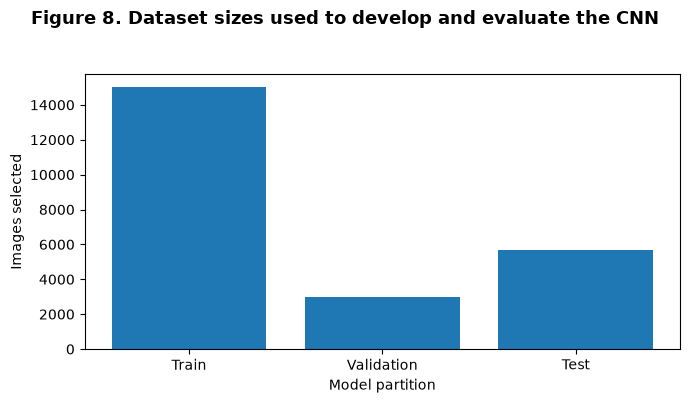

Saved: Figure_08_Dataset_sizes_used_to_develop_and_evaluate_the_CNN.png


In [19]:
# Keep the same original split and select each category without replacement.
if TRAIN_PER_CLASS + VAL_PER_CLASS > 1710:
    raise ValueError('The original training partition has 1,710 images per class.')

def stratified_pick(df, count_per_class, seed):
    groups = []
    for label, part in df.groupby('category_id'):
        n = len(part) if count_per_class is None else min(len(part), count_per_class)
        groups.append(part.sample(n=n, random_state=seed))
    return pd.concat(groups, ignore_index=True)

training_parts = []
validation_parts = []
for label, part in available_train.groupby('category_id'):
    n_required = TRAIN_PER_CLASS + VAL_PER_CLASS
    if len(part) < n_required:
        raise ValueError(f'Category {label} contains only {len(part)} usable training images. '
                         'Reduce TRAIN_PER_CLASS or VAL_PER_CLASS and try again.')
    selected = part.sample(n=n_required, random_state=SEED).reset_index(drop=True)
    training_parts.append(selected.iloc[:TRAIN_PER_CLASS])
    validation_parts.append(selected.iloc[TRAIN_PER_CLASS:])
train_df = pd.concat(training_parts, ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
val_df = pd.concat(validation_parts, ignore_index=True).reset_index(drop=True)
test_df = stratified_pick(test_listing.dropna(subset=['zip_member']).copy(), TEST_PER_CLASS, SEED)

assert not (set(train_df['filename']) & set(val_df['filename']))
assert not (set(train_df['filename']) & set(test_df['filename']))
assert not (set(val_df['filename']) & set(test_df['filename']))
assert len(train_df) >= 10_000
split_summary = pd.DataFrame({'partition': ['Train', 'Validation', 'Test'],
                              'sampled_records': [len(train_df), len(val_df), len(test_df)]})
display(split_summary)
split_summary.to_csv(OUT / 'model_partition_sizes.csv', index=False)
for name, df in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    df[['filename', 'category_id', 'category', 'zip_member']].to_csv(OUT / f'{name}_selected_images.csv', index=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(split_summary['partition'], split_summary['sampled_records'])
ax.set_xlabel('Model partition')
ax.set_ylabel('Images selected')
save_figure(8, 'Dataset sizes used to develop and evaluate the CNN', fig)

In [20]:
# Verify selected images before training so that broken files do not appear halfway through an epoch.
# This checks JPEG structure without loading every image into memory.
def filter_unreadable(frame, partition_name):
    bad = []
    with zipfile.ZipFile(archive_path, 'r') as za:
        for _, row in frame.iterrows():
            try:
                with za.open(row['zip_member']) as handle:
                    with Image.open(handle) as im:
                        im.verify()
            except Exception as exc:
                bad.append({'partition': partition_name, 'filename': row['filename'], 'error': str(exc)})
    good = frame.loc[~frame['filename'].isin({b['filename'] for b in bad})].copy().reset_index(drop=True)
    return good, bad

train_df, bad_train = filter_unreadable(train_df, 'train')
val_df, bad_val = filter_unreadable(val_df, 'validation')
test_df, bad_test = filter_unreadable(test_df, 'test')
pd.DataFrame(bad_train + bad_val + bad_test,
             columns=['partition', 'filename', 'error']).to_csv(OUT / 'unreadable_selected_images.csv', index=False)
print(f'Image verification complete: train={len(train_df)}, validation={len(val_df)}, test={len(test_df)}')
print('Files excluded due to read errors:', len(bad_train) + len(bad_val) + len(bad_test))
if min(len(train_df), len(val_df), len(test_df)) == 0:
    raise ValueError('A model partition is empty after checking the images.')

Image verification complete: train=15000, validation=3000, test=5700
Files excluded due to read errors: 0


In [27]:

# Prepare the image datasets for CNN training.
# Images are read directly from the ZIP archive to reduce memory usage.

def image_generator(frame):
    with zipfile.ZipFile(archive_path, 'r') as za:
        for member, label in frame[['zip_member', 'category_id']].itertuples(
            index=False, name=None
        ):
            image = read_cover(za, member).astype('float32') / 255.0
            yield image, np.int32(label)


def make_dataset(frame, shuffle=False, repeat=False):
    specification = (
        tf.TensorSpec((IMG_SIZE, IMG_SIZE, 3), tf.float32),
        tf.TensorSpec((), tf.int32)
    )

    ds = tf.data.Dataset.from_generator(
        lambda: image_generator(frame),
        output_signature=specification
    )

    if shuffle:
        ds = ds.shuffle(
            900,
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.batch(BATCH_SIZE)

    if repeat:
        ds = ds.repeat()

    return ds.prefetch(tf.data.AUTOTUNE)


# Finite datasets for prediction and evaluation.
train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

# Repeating datasets used only during model training.
train_fit_ds = make_dataset(train_df, shuffle=True, repeat=True)
val_fit_ds = make_dataset(val_df, repeat=True)

TRAIN_STEPS = math.ceil(len(train_df) / BATCH_SIZE)
VAL_STEPS = math.ceil(len(val_df) / BATCH_SIZE)

# Allow training figures to be regenerated with corrected results.
FIGURE_RECORDS[:] = [
    record for record in FIGURE_RECORDS
    if record['number'] <= 8
]

print('Training images:', len(train_df))
print('Validation images:', len(val_df))
print('Test images:', len(test_df))
print('Training steps per epoch:', TRAIN_STEPS)
print('Validation steps per epoch:', VAL_STEPS)
print('Datasets prepared successfully.')


Training images: 15000
Validation images: 3000
Test images: 5700
Training steps per epoch: 469
Validation steps per epoch: 94
Datasets prepared successfully.


## 7. Build the baseline CNN

The baseline model uses three convolutional layers to learn visual patterns, with pooling layers reducing the size of the intermediate feature maps. A global pooling layer summarises the learned features, and the final dense layer predicts one of the 30 categories using softmax probabilities.

I use categorical cross-entropy in its sparse form because the class labels are stored as integers. Adam is used to update the network weights. Accuracy is useful for an initial comparison because the original categories are balanced, but the final evaluation also examines macro precision, recall and F1-score.

In [22]:
NUM_CLASSES = 30

def build_baseline():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        tf.keras.layers.Conv2D(16, 3, padding='same', activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')
    ], name='baseline_cnn')

baseline = build_baseline()
baseline.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                 loss='sparse_categorical_crossentropy', metrics=['accuracy'])
baseline.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 96, 96, 16)          │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 48, 48, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 48, 48, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 24, 24, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 24, 24, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 12, 12, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 64)                  │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 30)                  │           1,950 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 29,694 (115.99 KB)

 Trainable params: 29,694 (115.99 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:

# Train the baseline CNN using the corrected dataset.

baseline_history = baseline.fit(
    train_fit_ds,
    validation_data=val_fit_ds,
    epochs=EPOCHS_BASELINE,
    steps_per_epoch=TRAIN_STEPS,
    validation_steps=VAL_STEPS,
    shuffle=False,
    verbose=1
)

pd.DataFrame(baseline_history.history).to_csv(
    OUT / 'baseline_training_history.csv',
    index=False
)


Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 53s 103ms/step - accuracy: 0.1063 - loss: 3.1842 - val_accuracy: 0.1050 - val_loss: 3.1960
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 47s 100ms/step - accuracy: 0.1098 - loss: 3.1616 - val_accuracy: 0.1010 - val_loss: 3.1984
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 52s 110ms/step - accuracy: 0.1203 - loss: 3.1429 - val_accuracy: 0.1140 - val_loss: 3.1677
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 46s 99ms/step - accuracy: 0.1216 - loss: 3.1303 - val_accuracy: 0.1120 - val_loss: 3.1751
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 44s 94ms/step - accuracy: 0.1288 - loss: 3.1155 - val_accuracy: 0.1130 - val_loss: 3.1645


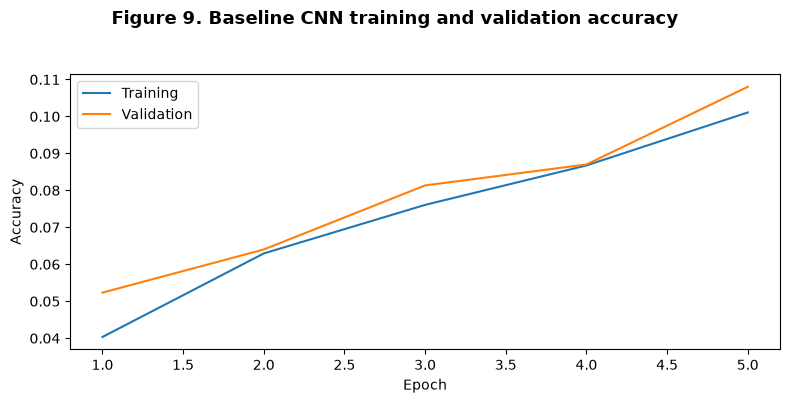

Saved: Figure_09_Baseline_CNN_training_and_validation_accuracy.png


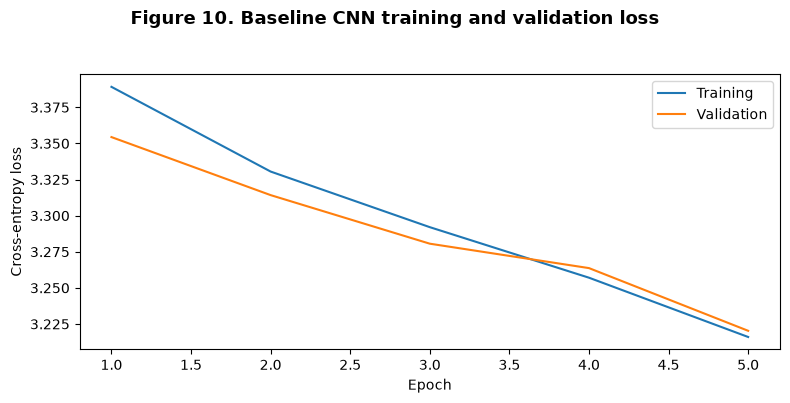

Saved: Figure_10_Baseline_CNN_training_and_validation_loss.png


In [24]:
def plot_history(history, accuracy_fig_no, loss_fig_no, model_name):
    h = history.history
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(range(1, len(h['accuracy']) + 1), h['accuracy'], label='Training')
    ax.plot(range(1, len(h['val_accuracy']) + 1), h['val_accuracy'], label='Validation')
    ax.set(xlabel='Epoch', ylabel='Accuracy')
    ax.legend()
    save_figure(accuracy_fig_no, f'{model_name} training and validation accuracy', fig)

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(range(1, len(h['loss']) + 1), h['loss'], label='Training')
    ax.plot(range(1, len(h['val_loss']) + 1), h['val_loss'], label='Validation')
    ax.set(xlabel='Epoch', ylabel='Cross-entropy loss')
    ax.legend()
    save_figure(loss_fig_no, f'{model_name} training and validation loss', fig)

plot_history(baseline_history, 9, 10, 'Baseline CNN')

## 8. Improve the CNN and compare validation performance

The second CNN adds batch normalisation, dropout and limited image augmentation. These changes are intended to improve generalisation by stabilising the training process and reducing overfitting. I use small rotations and zoom changes rather than horizontal flips because text and cover layout could be distorted by reversing the image.

This is an experiment rather than an assumption that a more complex network must perform better. I select the preferred model using validation macro F1-score and report both models' results.

In [25]:
def build_improved():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        tf.keras.layers.RandomRotation(0.03, seed=SEED),
        tf.keras.layers.RandomZoom(0.08, seed=SEED),
        tf.keras.layers.Conv2D(24, 3, padding='same', activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(48, 3, padding='same', activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(96, 3, padding='same', activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(96, activation='relu'),
        tf.keras.layers.Dropout(0.35),
        tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')
    ], name='improved_cnn')

improved = build_improved()
improved.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
                 loss='sparse_categorical_crossentropy', metrics=['accuracy'])
improved.summary()

Model: "improved_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ random_rotation (RandomRotation)     │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_zoom (RandomZoom)             │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 96, 96, 24)          │             672 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 96, 96, 24)          │              96 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 48, 48, 24)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 48, 48, 48)          │          10,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 48, 48, 48)          │             192 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 24, 24, 48)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 24, 24, 96)          │          41,568 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 24, 24, 96)          │             384 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 12, 12, 96)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 96)                  │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 96)                  │           9,312 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 96)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 30)                  │           2,910 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 65,550 (256.05 KB)

 Trainable params: 65,214 (254.74 KB)

 Non-trainable params: 336 (1.31 KB)

Epoch 1/7
469/469 ━━━━━━━━━━━━━━━━━━━━ 86s 177ms/step - accuracy: 0.1129 - loss: 3.1741 - val_accuracy: 0.1130 - val_loss: 3.1820
Epoch 2/7
469/469 ━━━━━━━━━━━━━━━━━━━━ 84s 180ms/step - accuracy: 0.1177 - loss: 3.1525 - val_accuracy: 0.1100 - val_loss: 3.2024
Epoch 3/7
469/469 ━━━━━━━━━━━━━━━━━━━━ 85s 182ms/step - accuracy: 0.1241 - loss: 3.1405 - val_accuracy: 0.1160 - val_loss: 3.1679
Epoch 4/7
469/469 ━━━━━━━━━━━━━━━━━━━━ 88s 189ms/step - accuracy: 0.1243 - loss: 3.1241 - val_accuracy: 0.1090 - val_loss: 3.2170
Epoch 5/7
469/469 ━━━━━━━━━━━━━━━━━━━━ 80s 171ms/step - accuracy: 0.1327 - loss: 3.1076 - val_accuracy: 0.1213 - val_loss: 3.1625
Epoch 6/7
469/469 ━━━━━━━━━━━━━━━━━━━━ 80s 171ms/step - accuracy: 0.1345 - loss: 3.0920 - val_accuracy: 0.1153 - val_loss: 3.1665
Epoch 7/7
469/469 ━━━━━━━━━━━━━━━━━━━━ 81s 172ms/step - accuracy: 0.1393 - loss: 3.0699 - val_accuracy: 0.1163 - val_loss: 3.1646


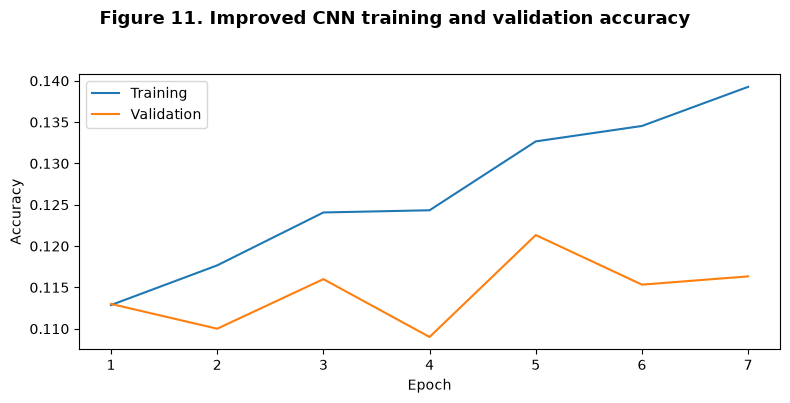

Saved: Figure_11_Improved_CNN_training_and_validation_accuracy.png


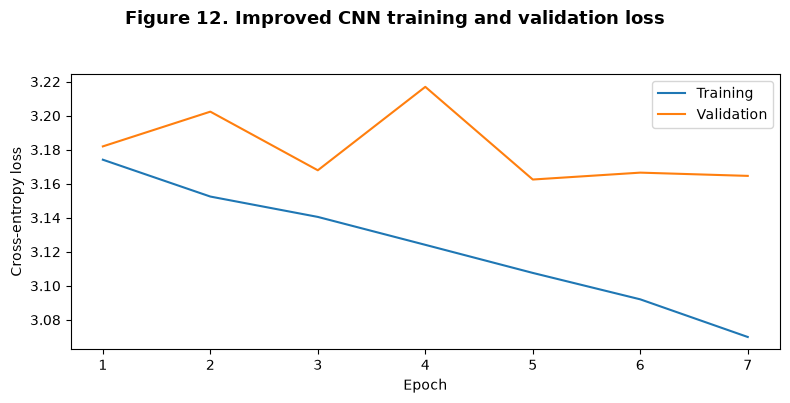

Saved: Figure_12_Improved_CNN_training_and_validation_loss.png


In [29]:

# Train the improved CNN using the corrected dataset.

improved_history = improved.fit(
    train_fit_ds,
    validation_data=val_fit_ds,
    epochs=EPOCHS_IMPROVED,
    steps_per_epoch=TRAIN_STEPS,
    validation_steps=VAL_STEPS,
    shuffle=False,
    verbose=1
)

pd.DataFrame(improved_history.history).to_csv(
    OUT / 'improved_training_history.csv',
    index=False
)

plot_history(improved_history, 11, 12, 'Improved CNN')


94/94 ━━━━━━━━━━━━━━━━━━━━ 8s 78ms/step


C:\Users\anphewa\AppData\Local\anaconda3\envs\pdan_cnn\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


94/94 ━━━━━━━━━━━━━━━━━━━━ 8s 75ms/step


C:\Users\anphewa\AppData\Local\anaconda3\envs\pdan_cnn\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


,model,accuracy,macro_precision,macro_recall,macro_f1
0,Baseline CNN,0.1130,0.0956,0.1130,0.0890
1,Improved CNN,0.1163,0.0895,0.1163,0.0856


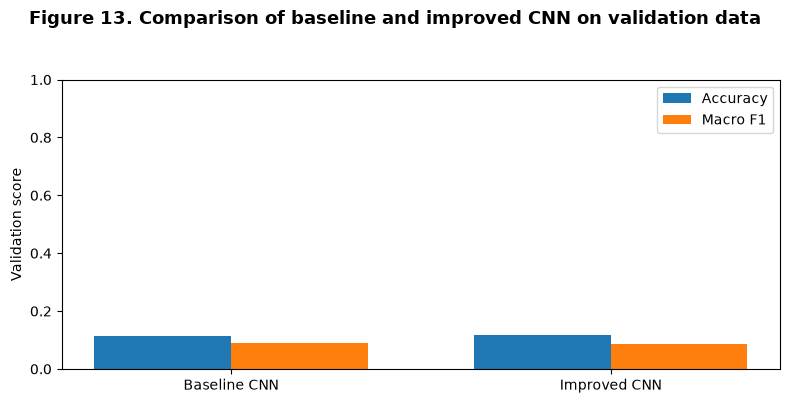

Saved: Figure_13_Comparison_of_baseline_and_improved_CNN_on_validation_data.png
Selected using validation macro F1: Baseline CNN


In [30]:
# The comparison uses validation records only. The official test set remains untouched.
def get_predictions(model, dataset):
    probabilities = model.predict(dataset, verbose=1)
    return probabilities.argmax(axis=1).astype(int), probabilities

y_val = val_df['category_id'].to_numpy(dtype=int)
base_val_pred, _ = get_predictions(baseline, val_ds)
impr_val_pred, _ = get_predictions(improved, val_ds)
assert len(base_val_pred) == len(y_val) == len(impr_val_pred)

validation_results = []
for name, pred in [('Baseline CNN', base_val_pred), ('Improved CNN', impr_val_pred)]:
    precision, recall, f1, _ = precision_recall_fscore_support(y_val, pred, average='macro', zero_division=0)
    validation_results.append({'model': name, 'accuracy': accuracy_score(y_val, pred),
                               'macro_precision': precision, 'macro_recall': recall, 'macro_f1': f1})
val_metrics = pd.DataFrame(validation_results)
val_metrics.to_csv(OUT / 'validation_model_comparison.csv', index=False)
display(val_metrics.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(val_metrics))
ax.bar(x - 0.18, val_metrics['accuracy'], width=0.36, label='Accuracy')
ax.bar(x + 0.18, val_metrics['macro_f1'], width=0.36, label='Macro F1')
ax.set_xticks(x, val_metrics['model'])
ax.set_ylabel('Validation score')
ax.set_ylim(0, 1)
ax.legend()
save_figure(13, 'Comparison of baseline and improved CNN on validation data', fig)

winner_name = val_metrics.sort_values(['macro_f1', 'accuracy'], ascending=False).iloc[0]['model']
selected_model = baseline if winner_name == 'Baseline CNN' else improved
print('Selected using validation macro F1:', winner_name)

## 9. Final evaluation on the official test partition

The selected model is evaluated once on the test partition provided by the dataset researchers. I report accuracy and macro-averaged precision, recall and F1-score. Macro averaging gives equal weight to each of the 30 categories, which is useful when considering whether the classifier performs consistently across different types of books.

The confusion matrix is used to identify which categories are often mistaken for one another. This matters for a publisher because incorrect category suggestions may affect cataloguing and make books harder for readers to find.

In [31]:
y_test = test_df['category_id'].to_numpy(dtype=int)
test_pred, test_prob = get_predictions(selected_model, test_ds)
assert len(y_test) == len(test_pred)
report_text = classification_report(y_test, test_pred, labels=list(range(NUM_CLASSES)),
                                    target_names=[category_lookup[i] for i in range(NUM_CLASSES)],
                                    digits=3, zero_division=0)
print('FINAL TEST EVALUATION:', winner_name)
print(report_text)
with open(OUT / 'test_classification_report.txt', 'w', encoding='utf-8') as f:
    f.write(f'Model chosen using validation data: {winner_name}\n\n{report_text}')
class_report = classification_report(y_test, test_pred, labels=list(range(NUM_CLASSES)),
                                     target_names=[category_lookup[i] for i in range(NUM_CLASSES)],
                                     output_dict=True, zero_division=0)
pd.DataFrame(class_report).T.to_csv(OUT / 'test_classification_report.csv')
summary = {'selected_model': winner_name,
           'n_train': len(train_df), 'n_validation': len(val_df), 'n_test': len(test_df),
           'accuracy': float(accuracy_score(y_test, test_pred)),
           'macro_precision': float(class_report['macro avg']['precision']),
           'macro_recall': float(class_report['macro avg']['recall']),
           'macro_f1': float(class_report['macro avg']['f1-score'])}
pd.DataFrame([summary]).to_csv(OUT / 'final_test_summary.csv', index=False)
display(pd.DataFrame([summary]).round(4))

179/179 ━━━━━━━━━━━━━━━━━━━━ 14s 78ms/step
FINAL TEST EVALUATION: Baseline CNN
                              precision    recall  f1-score   support

          Arts & Photography      0.167     0.032     0.053       190
       Biographies & Memoirs      0.098     0.179     0.126       190
            Business & Money      0.071     0.016     0.026       190
                   Calendars      0.134     0.100     0.114       190
            Children's Books      0.163     0.200     0.180       190
     Comics & Graphic Novels      0.151     0.342     0.210       190
      Computers & Technology      0.107     0.258     0.151       190
      Cookbooks, Food & Wine      0.212     0.111     0.145       190
      Crafts, Hobbies & Home      0.090     0.063     0.074       190
    Christian Books & Bibles      0.105     0.021     0.035       190
Engineering & Transportation      0.053     0.068     0.060       190
   Health, Fitness & Dieting      0.000     0.000     0.000       190
          

C:\Users\anphewa\AppData\Local\anaconda3\envs\pdan_cnn\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


,selected_model,n_train,n_validation,n_test,accuracy,macro_precision,macro_recall,macro_f1
0,Baseline CNN,15000,3000,5700,0.1226,0.1139,0.1226,0.096


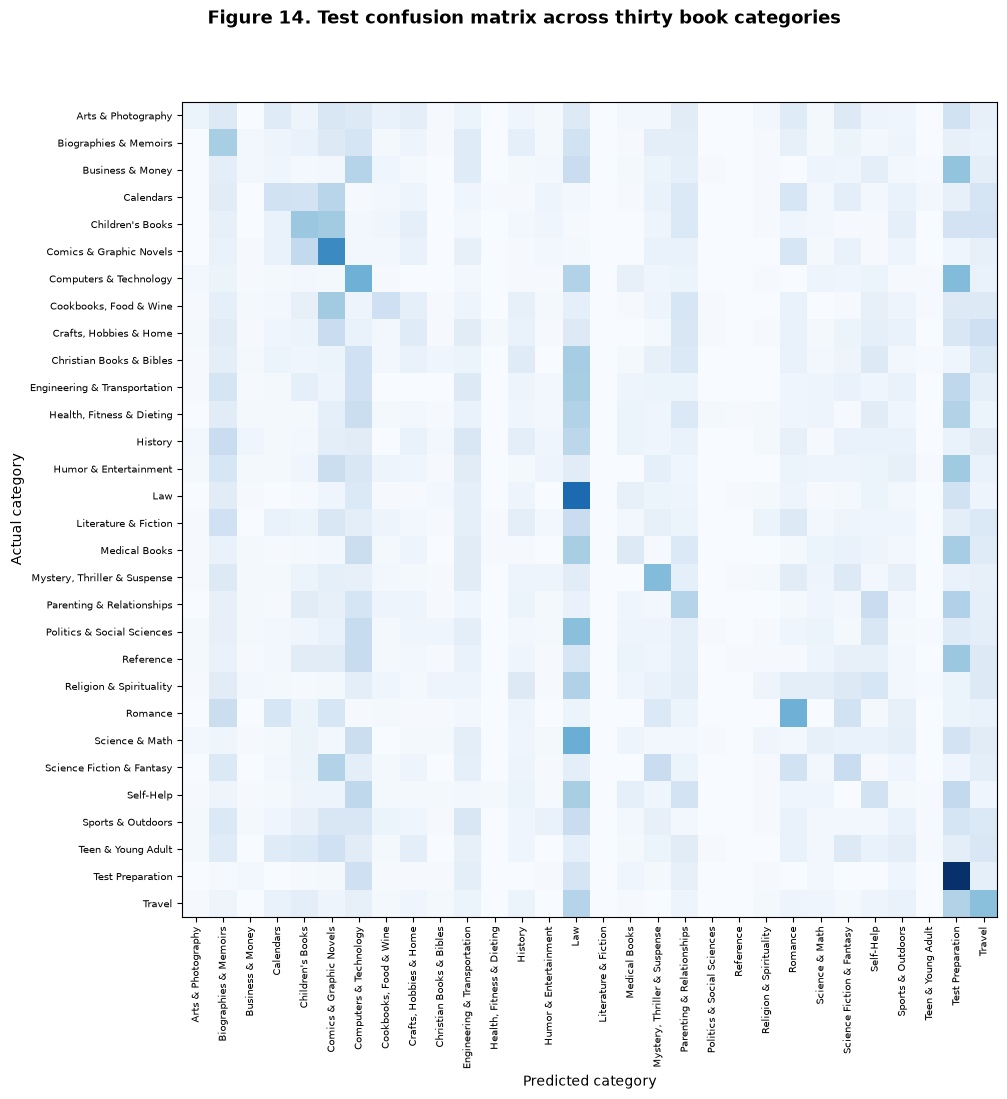

Saved: Figure_14_Test_confusion_matrix_across_thirty_book_categories.png


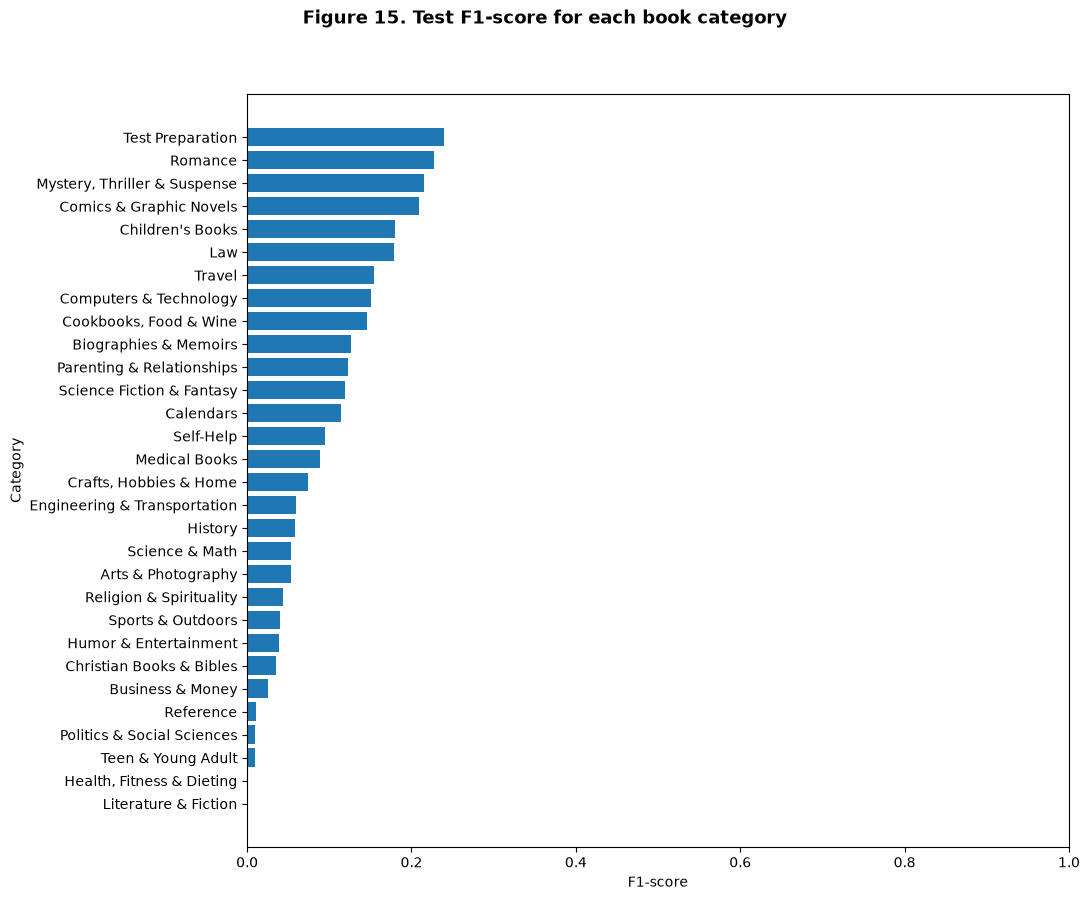

Saved: Figure_15_Test_F1_score_for_each_book_category.png


In [32]:
matrix = confusion_matrix(y_test, test_pred, labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(12, 11))
ax.imshow(matrix, cmap='Blues')
ax.set_xticks(range(NUM_CLASSES), [category_lookup[i] for i in range(NUM_CLASSES)], rotation=90, fontsize=7)
ax.set_yticks(range(NUM_CLASSES), [category_lookup[i] for i in range(NUM_CLASSES)], fontsize=7)
ax.set_xlabel('Predicted category')
ax.set_ylabel('Actual category')
save_figure(14, 'Test confusion matrix across thirty book categories', fig)

f1_by_category = pd.Series({name: class_report[name]['f1-score'] for name in
                            [category_lookup[i] for i in range(NUM_CLASSES)]}).sort_values()
fig, ax = plt.subplots(figsize=(11, 9))
ax.barh(f1_by_category.index, f1_by_category.values)
ax.set_xlabel('F1-score')
ax.set_ylabel('Category')
ax.set_xlim(0, 1)
save_figure(15, 'Test F1-score for each book category', fig)

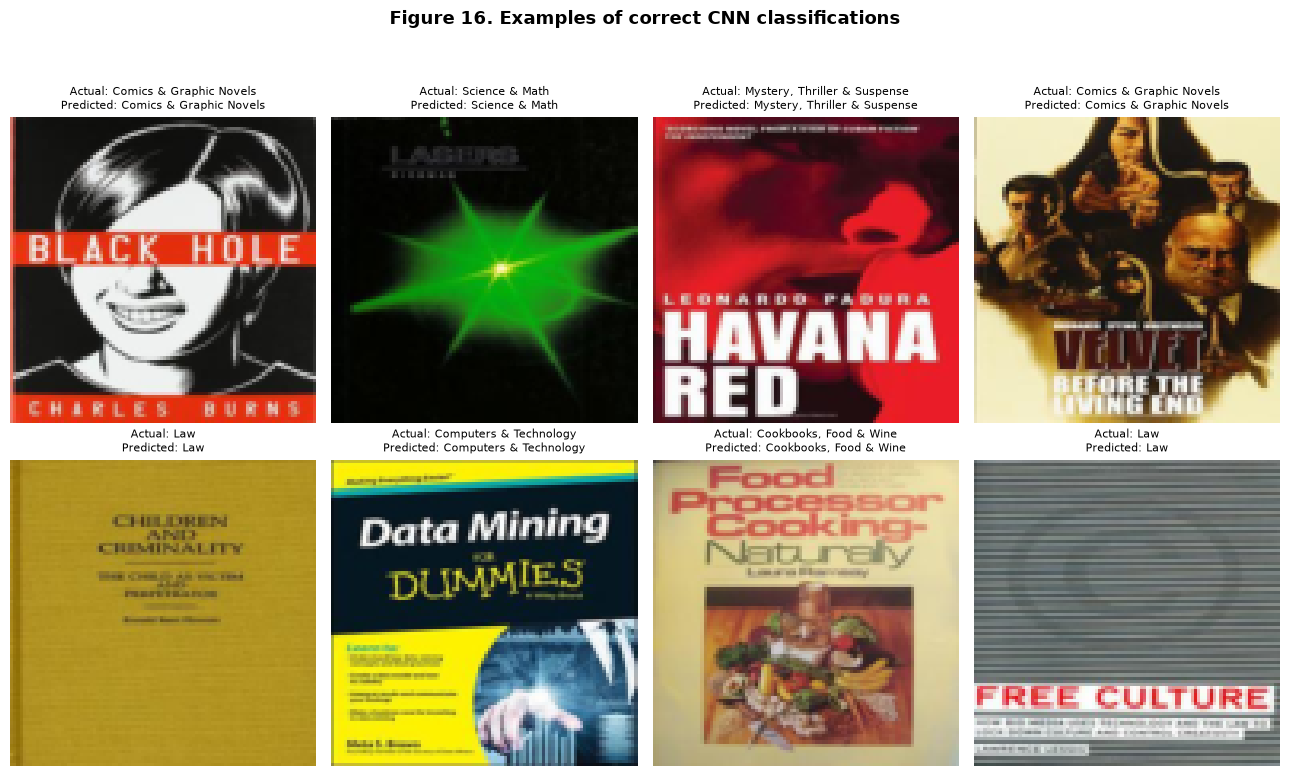

Saved: Figure_16_Examples_of_correct_CNN_classifications.png


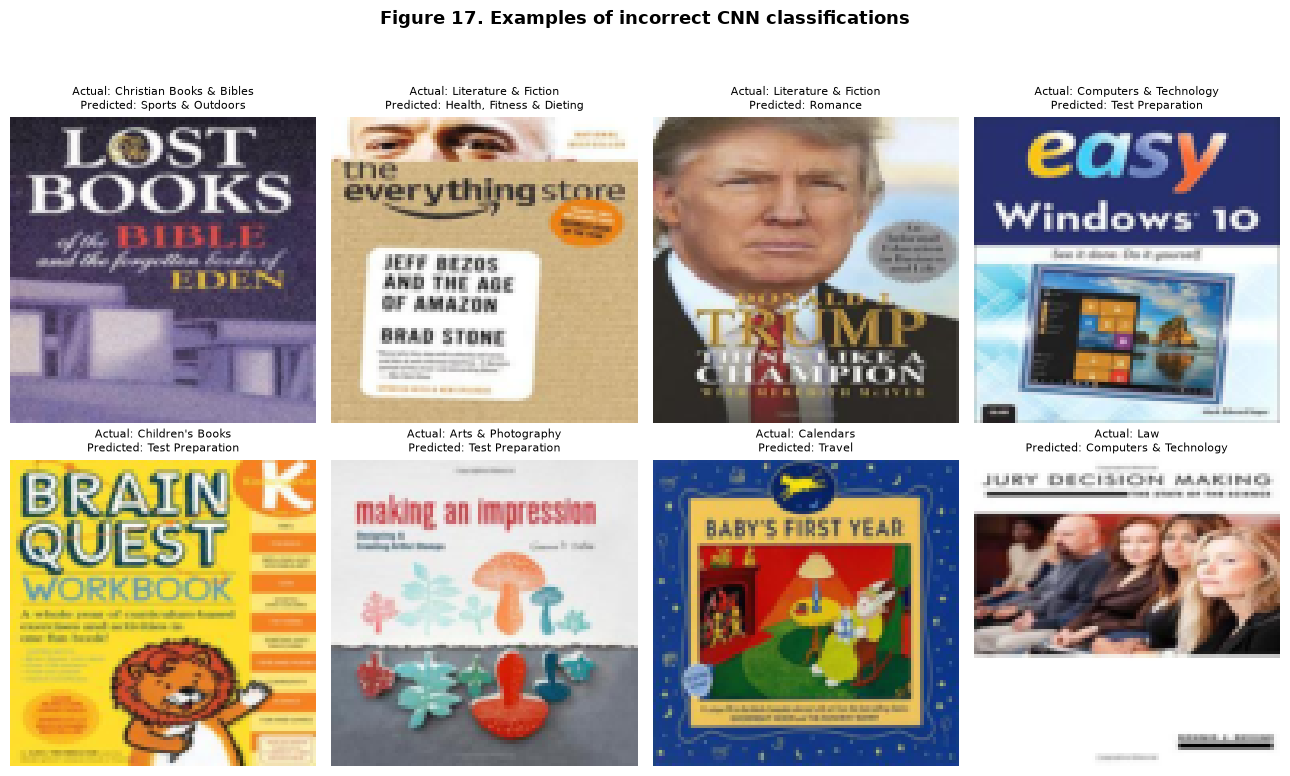

Saved: Figure_17_Examples_of_incorrect_CNN_classifications.png


In [33]:
# Show a small number of real test covers with actual and predicted categories.
prediction_table = test_df[['filename', 'category_id', 'zip_member']].copy()
prediction_table['predicted_id'] = test_pred
prediction_table['confidence'] = test_prob.max(axis=1)
prediction_table['correct'] = prediction_table['category_id'].eq(prediction_table['predicted_id'])
prediction_table.to_csv(OUT / 'test_predictions.csv', index=False)

def plot_examples(frame, figure_no, title, max_examples=8):
    sample = frame.sample(n=min(max_examples, len(frame)), random_state=SEED)
    fig, axes = plt.subplots(2, 4, figsize=(13, 8))
    for ax in axes.flat:
        ax.axis('off')
    with zipfile.ZipFile(archive_path, 'r') as za:
        for ax, (_, row) in zip(axes.flat, sample.iterrows()):
            ax.imshow(read_cover(za, row['zip_member']))
            actual = category_lookup[int(row['category_id'])]
            predicted = category_lookup[int(row['predicted_id'])]
            ax.set_title(f'Actual: {actual}\nPredicted: {predicted}', fontsize=8)
    save_figure(figure_no, title, fig)

if prediction_table['correct'].any():
    plot_examples(prediction_table[prediction_table['correct']], 16, 'Examples of correct CNN classifications')
else:
    print('No correct predictions available for Figure 16.')
if (~prediction_table['correct']).any():
    plot_examples(prediction_table[~prediction_table['correct']], 17, 'Examples of incorrect CNN classifications')
else:
    print('No incorrect predictions available for Figure 17.')

## 10. Interpretation and limitations

The results should be discussed using the figures and CSV outputs produced by this run. In particular, the final report should explain whether the improved model performed better on validation data, which categories the model recognised most reliably and where the most frequent errors occurred.

A cover-based model offers a practical starting point for automatically suggesting book categories, but it has important limitations. Book covers can use similar fonts, colours and layouts across genres. The dataset also consists of Amazon book listings, so its category labels may not represent a publisher's own catalogue. Image resizing may remove fine text and visual information. Finally, model performance on the historical test set does not establish how well it would work on newly designed covers from other markets.

The next step would be to compare the image-based results with a model that also uses book titles or descriptions. This could help distinguish categories that have overlapping visual styles. Such an extension would require a new experiment rather than being treated as a result of the current CNN.

In [34]:
# Save the best selected model, all figure captions, and a short evidence summary.
model_path = OUT / 'selected_bookcover30_cnn.keras'
selected_model.save(model_path)
fig_index = pd.DataFrame(FIGURE_RECORDS).sort_values('number')
fig_index.to_csv(OUT / 'figure_index.csv', index=False)
print('Saved model:', model_path)
print('Saved figures:', len(fig_index))
display(fig_index)

print('\nSummary for the academic report:')
print(f"Dataset: {spark_counts['total']:,} original records across {NUM_CLASSES} categories")
print(f"Train: {len(train_df):,}; validation: {len(val_df):,}; test: {len(test_df):,}")
print(f"Selected model: {winner_name}")
for metric in ['accuracy', 'macro_precision', 'macro_recall', 'macro_f1']:
    print(f"{metric}: {summary[metric]:.4f}")
print('The notebook completed. Save it now to retain the training and test outputs.')

Saved model: C:\Users\anphewa\PDAN8412_Part3_ST10123828_BookCover30\outputs\selected_bookcover30_cnn.keras
Saved figures: 15


,number,caption,file
0,1,Distribution of training covers by category,Figure_01_Distribution_of_training_covers_by_c...
1,2,Distribution of test covers by category,Figure_02_Distribution_of_test_covers_by_categ...
2,3,Missing metadata by original field,Figure_03_Missing_metadata_by_original_field.png
3,4,Image availability in the original training an...,Figure_04_Image_availability_in_the_original_t...
4,5,Examples of book covers from fifteen categories,Figure_05_Examples_of_book_covers_from_fifteen...
5,6,Average brightness of sampled book covers,Figure_06_Average_brightness_of_sampled_book_c...
6,7,Colour channel intensities in the image sample,Figure_07_Colour_channel_intensities_in_the_im...
7,8,Dataset sizes used to develop and evaluate the...,Figure_08_Dataset_sizes_used_to_develop_and_ev...
8,11,Improved CNN training and validation accuracy,Figure_11_Improved_CNN_training_and_validation...
9,12,Improved CNN training and validation loss,Figure_12_Improved_CNN_training_and_validation...



Summary for the academic report:
Dataset: 57,000 original records across 30 categories
Train: 15,000; validation: 3,000; test: 5,700
Selected model: Baseline CNN
accuracy: 0.1226
macro_precision: 0.1139
macro_recall: 0.1226
macro_f1: 0.0960
The notebook completed. Save it now to retain the training and test outputs.


## References

Iwana, B.K., Raza Rizvi, S.T., Ahmed, S., Dengel, A. and Uchida, S. 2016. Judging a book by its cover. *arXiv preprint*, arXiv:1610.09204. Available at: <https://arxiv.org/abs/1610.09204> [Accessed 17 November 2026].

Apache Software Foundation. 2026. *PySpark documentation*. [online] Available at: <https://spark.apache.org/docs/latest/api/python/> [Accessed 17 November 2026].

TensorFlow. 2026. *TensorFlow documentation*. [online] Available at: <https://www.tensorflow.org/api_docs> [Accessed 17 November 2026].

**Research note:** The models and figures should only be discussed after the relevant cells have run. The notebook deliberately contains no invented accuracy scores or pre-filled training outputs.